<a href="https://colab.research.google.com/github/Mittal-Sankalp/EDA-Campus-Crowd-Prediction/blob/main/Smart_Campus_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 43752 is the specific OpenML ID for the Campus Gym Crowd dataset
dataset = fetch_openml(data_id=43752, as_frame=True, parser='auto')
df = dataset.frame

# Data Loading & Initial Setup

In [7]:
print("Loading dataset from OpenML (ID: 43752)...")
dataset = fetch_openml(data_id=43752, as_frame=True, parser='auto')
df = dataset.frame

# Parse datetime and ensure chronological order
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
target = 'number_people'

Loading dataset from OpenML (ID: 43752)...


/tmp/ipykernel_1253/242716248.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'])
/tmp/ipykernel_1253/242716248.py:6: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df['date'] = pd.to_datetime(df['date'])


# Feature Engineering

In [8]:
print("Applying feature engineering (cyclical encoding, lags, rolling stats)...")

# 1. Force convert to datetime (handles timezone offsets automatically)
df['date'] = pd.to_datetime(df['date'], utc=True)

# 2. Sort chronologically
df = df.sort_values('date').reset_index(drop=True)

# 3. Extract temporal components (now .dt will work properly)
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute
df['day_of_week'] = df['date'].dt.dayofweek

# Cyclical Encoding
df['hour_sin'] = np.sin(2 * np.pi * (df['hour'] + df['minute']/60) / 24)
df['hour_cos'] = np.cos(2 * np.pi * (df['hour'] + df['minute']/60) / 24)
df['day_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['day_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)

# Lag Features (1 step = 10 mins)
df['crowd_10m_ago'] = df[target].shift(1)
df['crowd_1h_ago'] = df[target].shift(6)
df['crowd_24h_ago'] = df[target].shift(144)

# Rolling Windows (past 1 hour)
df['crowd_rolling_mean_1h'] = df[target].shift(1).rolling(window=6).mean()
df['crowd_rolling_std_1h'] = df[target].shift(1).rolling(window=6).std()

# Drop rows with NaN values from shifting
df = df.dropna().reset_index(drop=True)

# Define features
features = [
    'temperature', 'is_holiday', 'is_weekend', 'is_during_semester',
    'is_start_of_semester', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
    'crowd_10m_ago', 'crowd_1h_ago', 'crowd_24h_ago',
    'crowd_rolling_mean_1h', 'crowd_rolling_std_1h'
]

# Convert boolean flags to integers
for col in ['is_holiday', 'is_weekend', 'is_during_semester', 'is_start_of_semester']:
    if col in df.columns:
        df[col] = df[col].astype(int)

X = df[features]
y = df[target]

Applying feature engineering (cyclical encoding, lags, rolling stats)...


# Train / Test Split

In [9]:
print("Splitting data chronologically...")
split_idx = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_test = df['date'].iloc[split_idx:]

Splitting data chronologically...


# Hyperparameter Tuning with TimeSeriesSplit

In [10]:
print("Starting GridSearchCV with TimeSeriesSplit...")
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'learning_rate': [0.05, 0.1],
    'max_iter': [100, 200],
    'max_depth': [5, None],
    'l2_regularization': [0.0, 0.1]
}

base_model = HistGradientBoostingRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print("\n--- Tuning Results ---")
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Cross-Validation MAE: {-grid_search.best_score_:.2f} people")

Starting GridSearchCV with TimeSeriesSplit...
Fitting 5 folds for each of 16 candidates, totalling 80 fits

--- Tuning Results ---
Best Parameters: {'l2_regularization': 0.1, 'learning_rate': 0.05, 'max_depth': None, 'max_iter': 200}
Cross-Validation MAE: 4.05 people


# Final Evaluation on Unseen Test Data

In [11]:
print("\nEvaluating best model on test set...")
predictions = best_model.predict(X_test)
predictions = np.maximum(0, predictions)  # Crowd size cannot be negative

final_mae = mean_absolute_error(y_test, predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Final Test MAE: {final_mae:.2f} people")
print(f"Final Test RMSE: {final_rmse:.2f} people")


Evaluating best model on test set...
Final Test MAE: 2.92 people
Final Test RMSE: 4.42 people


# Visualization


Plotting 48-hour prediction window...


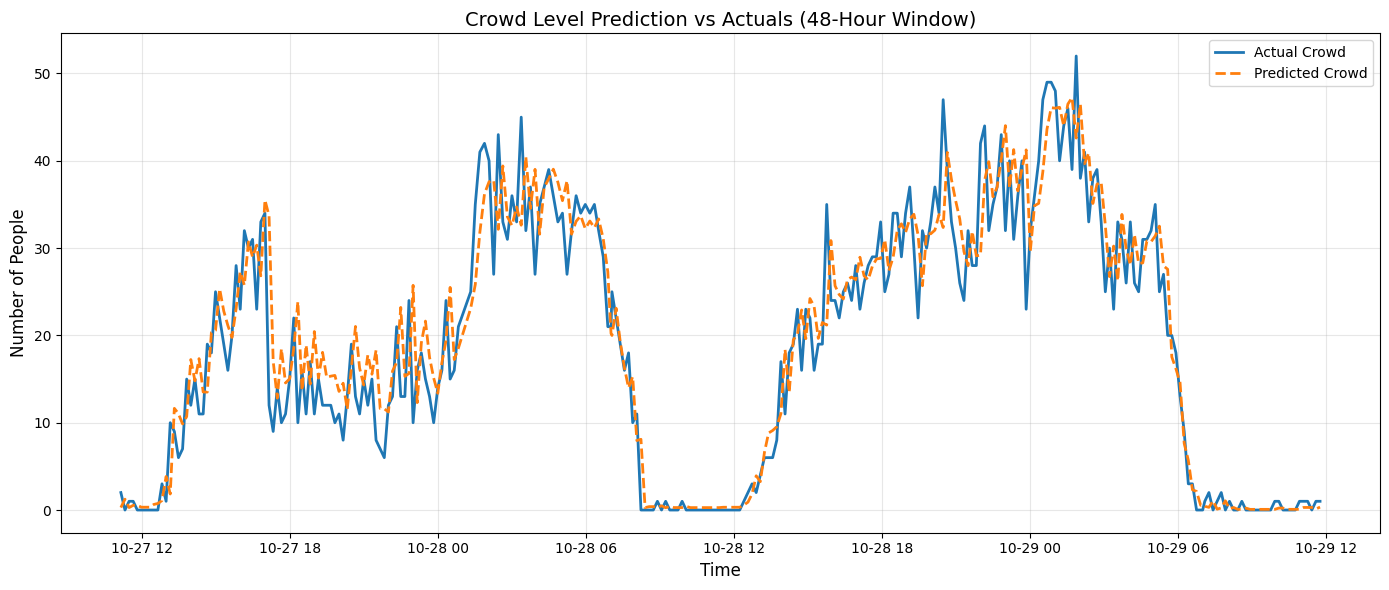

In [12]:
print("\nPlotting 48-hour prediction window...")
plot_window = 288  # 48 hours * 6 ten-minute intervals per hour

plt.figure(figsize=(14, 6))
plt.plot(dates_test.iloc[:plot_window], y_test.iloc[:plot_window], label='Actual Crowd', color='#1f77b4', linewidth=2)
plt.plot(dates_test.iloc[:plot_window], predictions[:plot_window], label='Predicted Crowd', color='#ff7f0e', linestyle='--', linewidth=2)

plt.title('Crowd Level Prediction vs Actuals (48-Hour Window)', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Number of People', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()